# Lineer Regression / Mpg Linear Regression

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** No local CSV/XLSX next to this notebook; see code for in-library/remote datasets..  
**Methods referenced:** `LinearRegression`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = sns.load_dataset("mpg")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [4]:
df.dropna(inplace = True)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model_year    392 non-null    int64  
 7   origin        392 non-null    object 
 8   name          392 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 30.6+ KB


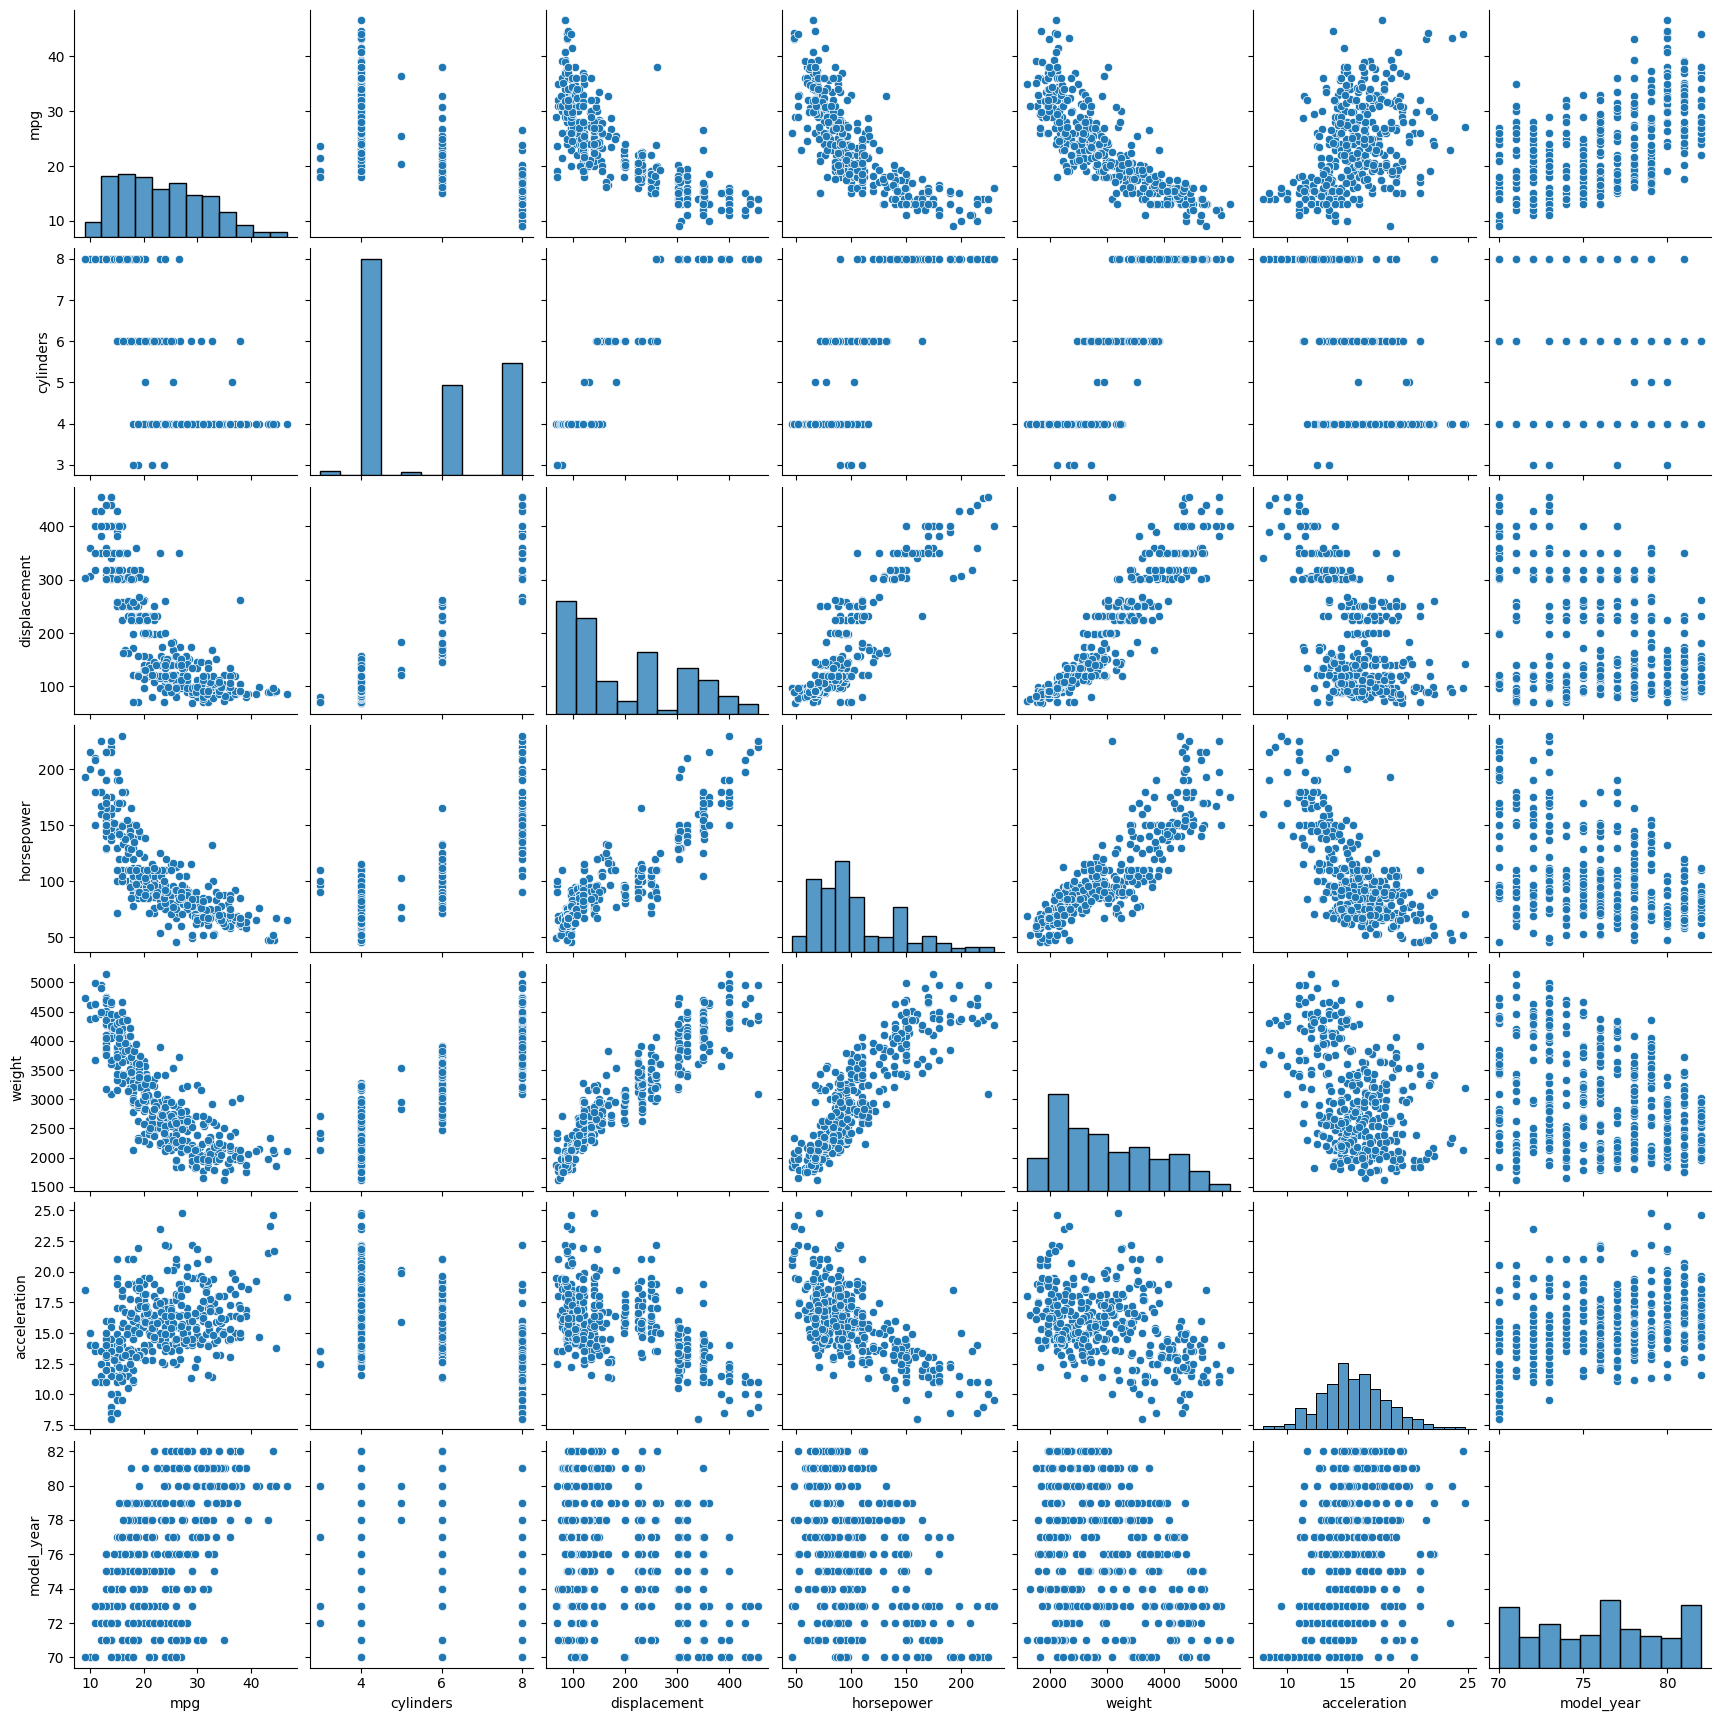

In [6]:
sns.pairplot(df)
plt.show()

In [7]:
df.corr(numeric_only = True)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.000000,-0.777618,-0.805127,-0.778427,-0.832244,0.423329,0.580541
cylinders,-0.777618,1.000000,0.950823,0.842983,0.897527,-0.504683,-0.345647
displacement,-0.805127,0.950823,1.000000,0.897257,0.932994,-0.543800,-0.369855
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361
weight,-0.832244,0.897527,0.932994,0.864538,1.000000,-0.416839,-0.309120
acceleration,0.423329,-0.504683,-0.543800,-0.689196,-0.416839,1.000000,0.290316
model_year,0.580541,-0.345647,-0.369855,-0.416361,-0.309120,0.290316,1.000000


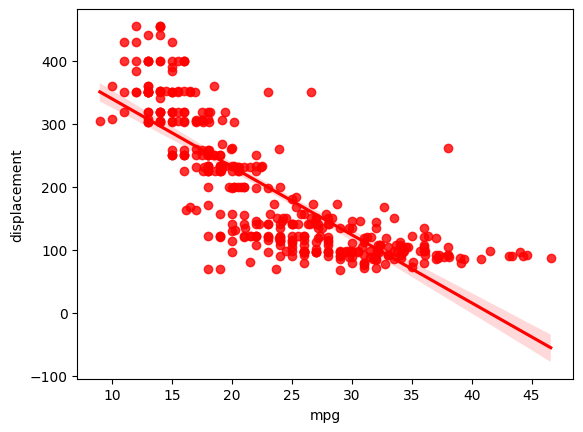

In [8]:
sns.regplot(x = df["mpg"], y = df["displacement"], color = "r")
plt.show()

### independent and dependent features

In [9]:
X = df[["displacement", "cylinders", "weight", "horsepower"]]
y = df["mpg"]

### train - test split

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 15)

In [12]:
from sklearn.preprocessing import StandardScaler

In [13]:
scaler = StandardScaler()

In [14]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [15]:
from sklearn.linear_model import LinearRegression

In [16]:
regression = LinearRegression()

In [17]:
regression.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [19]:
df["cylinders"].value_counts()

cylinders
4    199
8    103
6     83
3      4
5      3
Name: count, dtype: int64

In [20]:
threehundred_scaled = scaler.transform([[350, 8, 3000, 170]]) 
# displacement, cylinders, weight, hp

c:\Users\emres\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [21]:
real_pred = regression.predict(threehundred_scaled)
print("real prediction: ", real_pred)

real prediction:  [19.88720248]


### prediction

In [22]:
y_pred = regression.predict(X_test)

In [23]:
y_pred

array([17.20094072, 30.29756273, 31.81690228, 20.15821418, 15.9352527 ,
       29.89811473, 28.41213183, 28.00988215, 13.14340256, 23.64150787,
       12.38180983, 18.41064825, 25.31421455, 24.0525207 , 24.73822746,
       23.82268148, 21.89982107, 26.29148467, 29.46333044, 19.6275819 ,
       16.98780247, 29.05533172, 28.34702879, 11.48068718, 30.62336657,
       25.14411796, 29.35824254, 19.03090291, 27.58002761, 31.57567257,
       13.63892414,  9.57462669, 30.00538131, 18.06429013, 18.52428033,
       29.99243925, 23.202714  , 29.45536462, 20.67715929, 30.14335282,
       21.41758434, 22.52693454, 14.06339323, 25.67857864, 31.82715573,
       24.06488657, 23.27760899, 14.23984055, 16.8478242 , 18.41618623,
       31.59863766, 23.52015686, 15.2575291 , 24.42337434, 14.65153538,
        9.53441608, 29.30243057, 23.02456256, 31.03933966, 30.48808093,
       29.55130342, 14.45170586, 20.78178699, 30.91834966, 14.60136228,
       24.6796837 , 10.37454649, 24.84913486, 23.59469359, 22.04

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [25]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
print("mse: ", mse)
print("mae: ", mae)

mse:  22.64193247395339
mae:  3.401471698724532


In [26]:
score = r2_score(y_test, y_pred)
print("score: ", score)

score:  0.6590610390675664


In [27]:
regression.intercept_

np.float64(23.602040816326532)

In [28]:
print(regression.coef_)

[-0.41834546 -0.31340858 -4.57301536 -1.40211946]


In [29]:
1 - (1 - score) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1)

0.6443969977371391